# 04 — Multivariate Forecasting
Test whether market and macroeconomic indicators improve on the univariate baseline. All predictors enter as lagged observations. We explicitly compare the Japan lithium carbonate import-price index included versus excluded.

In [1]:
from pathlib import Path
import warnings
warnings.filterwarnings("ignore")
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

DATA_FILE = Path("../data/lithium_consolidated_monthly.csv")
TARGET = "Selected lithium carbonate price (CNY/t)"
JAPAN_INDEX = "Japan, Import Prices, Yen Basis, Lithium Carbonates, Index, 2020 = 100"
RANDOM_STATE = 42

df = pd.read_csv(DATA_FILE)
df["Month"] = pd.to_datetime(df["Month"])
df = df.sort_values("Month").drop_duplicates("Month").set_index("Month").asfreq("MS")
df[TARGET] = pd.to_numeric(df[TARGET], errors="coerce")

from sklearn.pipeline import make_pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression, Ridge
from sklearn.neighbors import KNeighborsRegressor
from sklearn.ensemble import RandomForestRegressor, GradientBoostingRegressor
from sklearn.svm import SVR
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

EXCLUDED = {
    TARGET, "Selected target source",
    "Lithium carbonate price (CNY/metric tonne)",
    "China spot lithium carbonate price (CNY/t) - CSV",
    "OLD - faulty cobalt settlement series (constant; excluded)",
    "China spot price open (CNY/t) - CSV",
    "China spot price high (CNY/t) - CSV",
    "China spot price low (CNY/t) - CSV",
    "China spot price volume (CSV)",
    "China spot price change (%) - CSV",
}
ALL_PREDICTORS = [c for c in df.select_dtypes(include=np.number).columns if c not in EXCLUDED]

def make_supervised(horizon=1, n_lags=6, exog_cols=None):
    """At month t, use target/predictor observations through t to predict target at t+h."""
    X = pd.DataFrame(index=df.index)
    for lag in range(0, n_lags):
        X[f"target_lag_{lag}"] = df[TARGET].shift(lag)
    if exog_cols:
        for col in exog_cols:
            for lag in range(1, n_lags + 1):
                X[f"{col}_lag_{lag}"] = pd.to_numeric(df[col], errors="coerce").shift(lag)
    y = df[TARGET].shift(-horizon).rename("target")
    data = X.join(y).dropna(subset=["target"])
    # Do not require every optional predictor to be present. Missing features are imputed within each training fold.
    return data.drop(columns="target"), data["target"]

def split_time(X, y, test_fraction=0.2):
    split = int(len(X) * (1-test_fraction))
    return X.iloc[:split], X.iloc[split:], y.iloc[:split], y.iloc[split:]

def model_bank():
    return {
        "Linear Regression": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), LinearRegression()),
        "Ridge": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), Ridge(alpha=10)),
        "KNN": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), KNeighborsRegressor(n_neighbors=5)),
        "SVR": make_pipeline(SimpleImputer(strategy="median"), StandardScaler(), SVR(C=10, epsilon=0.1)),
        "Random Forest": make_pipeline(SimpleImputer(strategy="median"), RandomForestRegressor(n_estimators=300, min_samples_leaf=2, random_state=RANDOM_STATE)),
        "Gradient Boosting": make_pipeline(SimpleImputer(strategy="median"), GradientBoostingRegressor(random_state=RANDOM_STATE)),
    }

def score_predictions(y_true, pred):
    return {"MAE": mean_absolute_error(y_true, pred),
            "RMSE": mean_squared_error(y_true, pred)**0.5,
            "R2": r2_score(y_true, pred)}

## 1. Choose predictor sets

In [2]:
# Restrict to variables with at least 60 observed monthly values; the model pipeline handles remaining gaps.
coverage = df[ALL_PREDICTORS].notna().sum()
base_predictors = [c for c in ALL_PREDICTORS if coverage[c] >= 60 and c != JAPAN_INDEX]
with_japan = base_predictors + ([JAPAN_INDEX] if JAPAN_INDEX in ALL_PREDICTORS else [])
print("Base predictors:", len(base_predictors))
print("Japan index available:", JAPAN_INDEX in with_japan)
print("Japan index coverage:", df[JAPAN_INDEX].notna().sum() if JAPAN_INDEX in df else "not found")

Base predictors: 21
Japan index available: True
Japan index coverage: 201


## 2. Model benchmark (1, 3, 6, 12 months)

In [3]:
HORIZONS = [1, 3, 6, 12]
feature_sets = {"Multivariate — without Japan index": base_predictors,
                "Multivariate — with Japan index": with_japan}
results, predictions = [], {}
for set_name, cols in feature_sets.items():
    for h in HORIZONS:
        X, y = make_supervised(horizon=h, n_lags=6, exog_cols=cols)
        X_train, X_test, y_train, y_test = split_time(X, y)
        for name, model in model_bank().items():
            model.fit(X_train, y_train)
            pred = model.predict(X_test)
            results.append({"Feature set": set_name, "Horizon (months)": h, "Model": name, **score_predictions(y_test, pred)})
            predictions[(set_name, h, name)] = (y_test, pred)
results = pd.DataFrame(results).sort_values(["Horizon (months)", "Feature set", "RMSE"])
display(results)

,Feature set,Horizon (months),Model,MAE,RMSE,R2
29,Multivariate — with Japan index,1,Gradient Boosting,5.499741e+04,5.948784e+04,-0.066899
27,Multivariate — with Japan index,1,SVR,7.529769e+04,9.479720e+04,-1.709306
28,Multivariate — with Japan index,1,Random Forest,1.159352e+05,1.204372e+05,-3.373087
25,Multivariate — with Japan index,1,Ridge,1.362377e+05,1.535971e+05,-6.112675
24,Multivariate — with Japan index,1,Linear Regression,2.373060e+05,2.605531e+05,-19.467253
26,Multivariate — with Japan index,1,KNN,2.931029e+05,3.038852e+05,-26.841078
5,Multivariate — without Japan index,1,Gradient Boosting,8.248069e+04,8.742057e+04,-1.304063
3,Multivariate — without Japan index,1,SVR,7.529760e+04,9.479708e+04,-1.709299
4,Multivariate — without Japan index,1,Random Forest,1.170481e+05,1.217156e+05,-3.466422
1,Multivariate — without Japan index,1,Ridge,1.449860e+05,1.617499e+05,-6.887788


## 3. Does the Japan index help?

In [4]:
best_by_set = results.loc[results.groupby(["Feature set","Horizon (months)"])["RMSE"].idxmin()]
display(best_by_set.sort_values(["Horizon (months)","Feature set"]))
wide = best_by_set.pivot(index="Horizon (months)", columns="Feature set", values="RMSE")
wide["RMSE difference (with Japan - without Japan)"] = wide["Multivariate — with Japan index"] - wide["Multivariate — without Japan index"]
display(wide)

,Feature set,Horizon (months),Model,MAE,RMSE,R2
29,Multivariate — with Japan index,1,Gradient Boosting,54997.410647,59487.841531,-0.066899
5,Multivariate — without Japan index,1,Gradient Boosting,82480.687833,87420.565458,-1.304063
33,Multivariate — with Japan index,3,SVR,74904.789898,94485.765947,-1.691534
9,Multivariate — without Japan index,3,SVR,74905.887302,94486.570874,-1.691580
39,Multivariate — with Japan index,6,SVR,71910.872144,90939.901824,-1.668654
15,Multivariate — without Japan index,6,SVR,71912.754111,90941.345121,-1.668739
45,Multivariate — with Japan index,12,SVR,61404.789999,78238.582701,-1.603992
21,Multivariate — without Japan index,12,SVR,61401.810586,78236.243983,-1.603836


Feature set,Multivariate — with Japan index,Multivariate — without Japan index,RMSE difference (with Japan - without Japan)
Horizon (months),,,
1,59487.841531,87420.565458,-27932.723927
3,94485.765947,94486.570874,-0.804927
6,90939.901824,90941.345121,-1.443297
12,78238.582701,78236.243983,2.338718


**How to interpret:** a lower RMSE with Japan means the index improved this particular chronological test comparison. It does not prove the index causes lithium carbonate price movements. Since the Japan index is a yen-denominated import-price index (not a direct spot quote), it is an auxiliary signal rather than an interchangeable target.

## 4. Plot best one-month-ahead multivariate model

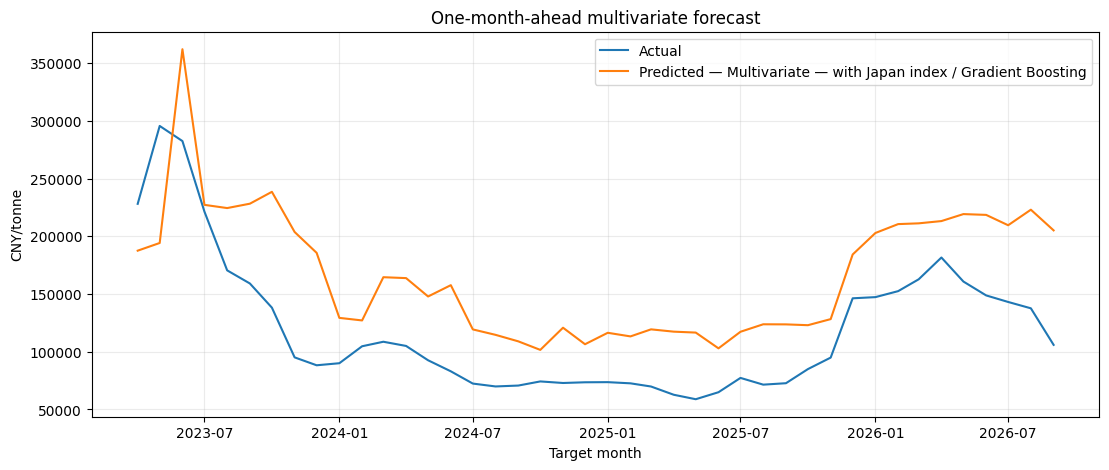

In [5]:
h=1
row = best_by_set[best_by_set["Horizon (months)"]==h].sort_values("RMSE").iloc[0]
key=(row["Feature set"], h, row["Model"])
y_test, pred=predictions[key]
fig, ax=plt.subplots(figsize=(13,5))
ax.plot(y_test.index,y_test.values,label="Actual")
ax.plot(y_test.index,pred,label=f"Predicted — {row['Feature set']} / {row['Model']}")
ax.set(title="One-month-ahead multivariate forecast",xlabel="Target month",ylabel="CNY/tonne")
ax.legend(); ax.grid(alpha=.25); plt.show()

## 5. Save results

In [6]:
results.to_csv("../results/multivariate_model_comparison.csv", index=False)
best_by_set.to_csv("../results/multivariate_best_by_feature_set.csv", index=False)
print("Saved multivariate results.")

Saved multivariate results.
